# 1.  What is the difference between K-Means and Hierarchical Clustering? Provide a use case for each?

- Difference Between K-Means and Hierarchical Clustering

Both K-Means and Hierarchical Clustering are unsupervised machine learning algorithms used to group similar data points into clusters. However, they work differently.

1. K-Means Clustering

K-Means divides the data into a predefined number of clusters, K.

How it works

1. Choose the number of clusters, K.

2. Randomly initialize K cluster centroids.

3. Assign each data point to its nearest centroid.

4. Recalculate the centroids.

5. Repeat the assignment and centroid calculation until the clusters stabilize.

For example, if K = 3:

Data → K-Means → Cluster 1
                
                Cluster 2
                
                Cluster 3

Use case:
A retail company can use K-Means to segment customers based on spending behavior, purchase frequency, and income.

For example:

Cluster 1 → Low-spending customers

Cluster 2 → Regular customers

Cluster 3 → High-value customers

2. Hierarchical Clustering

Hierarchical clustering creates a hierarchy of clusters rather than requiring the final number of clusters to be specified initially.

A common approach is agglomerative hierarchical clustering:

1. Start with every data point as its own cluster.

2. Find the two most similar clusters.

3. Merge them.

4. Continue merging until all points form one cluster.

5. Represent the process using a dendrogram.

Individual points

       ↓

Small clusters

       ↓

Larger clusters

       ↓

One large cluster

The dendrogram can then be "cut" at a particular level to obtain the desired number of clusters.

Use case:

In biology/genomics, hierarchical clustering can be used to group genes or patients according to similarities in gene-expression patterns. The dendrogram can reveal relationships at different levels of similarity.

Key Differences

| Feature            | K-Means                                    | Hierarchical Clustering                               |
| ------------------ | ------------------------------------------ | ----------------------------------------------------- |
| Type               | Partition-based                            | Hierarchical                                          |
| Number of clusters | Usually specified beforehand               | Can be chosen after creating hierarchy                |
| Output             | K clusters                                 | Dendrogram/tree                                       |
| Approach           | Iteratively updates centroids              | Repeatedly merges or splits clusters                  |
| Scalability        | Generally faster for large datasets        | Usually more computationally expensive                |
| Visualization      | Cluster plots                              | Dendrogram                                            |
| Cluster shape      | Works best with roughly spherical clusters | Can capture different structures depending on linkage |
| Typical use        | Customer segmentation                      | Gene/patient similarity analysis                      |

Simple way to remember

K-Means: "I know I want K groups—find them."
Hierarchical: "Show me how the data points are related, and I'll decide where to cut the hierarchy."

Example use cases:

K-Means → Customer segmentation based on purchasing behavior.

Hierarchical clustering → Gene-expression analysis to discover groups of similar genes or patients.


# 2. Explain the purpose of the Silhouette Score in evaluating clustering algorithms.

- Silhouette Score

The Silhouette Score is a metric used to evaluate the quality of clusters produced by a clustering algorithm such as K-Means or Hierarchical Clustering.

It measures two things:

1. Cohesion – how close a data point is to other points in its own cluster.

2. Separation – how far a data point is from points in the nearest other cluster.

Silhouette Score Formula

For a data point:

$$ S = \frac{b-a}{\max(a,b)} $$

Where:

a = average distance between the point and other points in its own cluster
b = average distance between the point and points in the nearest neighboring cluster

The score ranges from -1 to +1.

Interpretation

| Silhouette Score | Interpretation                                         |
| ---------------: | ------------------------------------------------------ |
|  Close to **+1** | Very well-separated and cohesive clusters              |
|     Around **0** | Clusters overlap or points lie near cluster boundaries |
|      Below **0** | Points may have been assigned to the wrong cluster     |


Example

Suppose we run K-Means with different values of K:

|  K | Silhouette Score |
| -: | ---------------: |
|  2 |             0.42 |
|  3 |             0.61 |
|  4 |             0.48 |
|  5 |             0.39 |


Here, K = 3 has the highest Silhouette Score, indicating that the observations form relatively cohesive and well-separated groups at that value of K.

Why is it useful?

The Silhouette Score can help us:

- Evaluate how well-defined clusters are.

- Compare different clustering algorithms.

- Help select an appropriate number of clusters.

- Detect overlapping or poorly separated clusters.

For example:

K-Means

   ↓

Try K = 2, 3, 4, 5

   ↓

Calculate Silhouette Score

   ↓

Compare scores

   ↓

Choose a clustering configuration with strong

cohesion and separation

Important limitation

A higher Silhouette Score does not automatically mean the clustering is more meaningful for the business or scientific problem. The metric is based on distances and cluster structure, so it should be considered alongside domain knowledge and other evaluation methods.

In short:

The Silhouette Score measures how well each data point fits within its own cluster compared with neighboring clusters. Scores closer to +1 generally indicate better-defined clustering, while scores near 0 or below indicate overlapping or poorly separated clusters.



# 3. What are the core parameters of DBSCAN, and how do they influence the clustering process?

- Core Parameters of DBSCAN

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a density-based clustering algorithm. Unlike K-Means, it does not require you to specify the number of clusters in advance and can identify some observations as noise or outliers.

The two main parameters are eps (ε) and min_samples.

1. eps (ε)

eps defines the maximum distance around a data point to be considered its neighborhood.

In simple terms:

eps determines how close points need to be to each other to be considered neighbors.

For example:

Small eps

   ↓

Only very close points are neighbors

   ↓

More small clusters + more noise



Large eps

   ↓

More points become neighbors

   ↓

Larger/fewer clusters + potentially less noise

If eps is too small, many points may be classified as noise.

If eps is too large, separate clusters may get merged.

2. min_samples

min_samples specifies the minimum number of points required within the eps neighborhood for a point to be considered a core point.

For example:

DBSCAN(eps=0.5, min_samples=5)

This means a point needs at least 5 observations in its neighborhood (including itself, as implemented by scikit-learn) to qualify as a core point.

A larger min_samples generally means:

- Higher density is required.

- More points may be classified as noise.

- Small or sparse clusters may be eliminated.

A smaller value can allow less-dense clusters to form but may make the algorithm more sensitive to noise.

How DBSCAN Classifies Points

DBSCAN divides observations into three categories:

Core Point

Has at least min_samples points within its eps neighborhood.

Border Point

Does not have enough neighbors to be a core point itself but lies within the neighborhood of a core point.

Noise Point

Does not belong to a sufficiently dense region and is not reachable from a core point.

        Core ● ● ●
             ● ●
           ●
        Border ○

                         × Noise


Example

Suppose:


In [3]:
from sklearn.cluster import DBSCAN

model = DBSCAN(
    eps=0.5,
    min_samples=5
)

The algorithm searches for regions where observations are sufficiently close together.

Changing the parameters changes the result:

| Parameter     | Smaller value                                 | Larger value                                      |
| ------------- | --------------------------------------------- | ------------------------------------------------- |
| `eps`         | Smaller neighborhoods, potentially more noise | Larger neighborhoods, potentially merged clusters |
| `min_samples` | Easier to form dense regions                  | Requires denser regions, potentially more noise   |


Choosing the parameters

A common approach for selecting eps is to examine a k-distance plot and look for an "elbow" where distances begin to increase sharply. min_samples can then be chosen based on dataset size, dimensionality, and domain knowledge.

Also, because DBSCAN relies on distances, feature scaling is usually important when variables have different units or ranges.

In short

eps controls the size of the neighborhood, while min_samples controls how dense that neighborhood must be to form a cluster.

Together, these parameters determine which regions DBSCAN considers dense clusters, which points are border points, and which observations are treated as noise.


# 4.  Why is feature scaling important when applying clustering algorithms like K-Means and DBSCAN?

- Why Feature Scaling Is Important in Clustering

Feature scaling is important for clustering algorithms such as K-Means and DBSCAN because both rely on distance calculations. If features have very different numerical ranges, a feature with larger values can dominate the distance calculation.

Example

Suppose we want to cluster customers using:

| Customer | Age | Annual Income |
| -------- | --: | ------------: |
| A        |  25 |        30,000 |
| B        |  30 |        32,000 |


The difference in:

- Age = 5
- Income = 2,000

If we calculate Euclidean distance directly, the income feature will have a much greater influence because its numerical values are much larger.

As a result, the algorithm may effectively ignore the contribution of Age.

How Scaling Solves the Problem

A common approach is StandardScaler, which transforms each feature approximately to:

$$ z=\frac{x-\mu}{\sigma} $$

where:

- x = original value
- μ = feature mean
- σ = feature standard deviation

After scaling:

Age             → comparable scale

Annual Income   → comparable scale

Now both features can contribute more fairly to the distance calculation.

Effect on K-Means

K-Means assigns observations to clusters based on their distance from cluster centroids.

Without scaling:

Large-scale feature

       ↓

Dominates distance

       ↓

Poor cluster assignments

With scaling:

Features on comparable scales

       ↓

More balanced distances

       ↓

More meaningful clusters

Therefore, scaling can substantially change the positions of the centroids and the resulting clusters.


- Effect on DBSCAN

DBSCAN uses eps, which defines the radius of a neighborhood.

Without scaling, a large-scale feature can dominate the distance:

Different feature scales

        ↓

Distorted distances

        ↓

Incorrect neighborhood density

        ↓

Poor clusters / excessive noise

Scaling makes the eps neighborhood more meaningful across features.

This is particularly important because choosing eps depends directly on the distance structure of the data.

Example

Imagine clustering customers using:

Age:              18–70

Income:           ₹20,000–₹1,000,000

Spending Score:   1–100

Without scaling, Income could dominate the distance calculations.

With scaling:

Age ────────┐

Income ──────┼──→ Balanced distance calculation

Spending Score ─┘

This allows K-Means or DBSCAN to consider the features more comparably.

K-Means vs. DBSCAN

| Algorithm   | Why scaling matters                                                          |
| ----------- | ---------------------------------------------------------------------------- |
| **K-Means** | Prevents large-scale features from dominating distances to centroids         |
| **DBSCAN**  | Prevents large-scale features from distorting neighborhood density and `eps` |
| **Both**    | Makes distance calculations more meaningful                                  |


Important exception

Scaling is not automatically required for every clustering problem. If all features are already measured on comparable scales and units, additional scaling may have little effect. The appropriate transformation also depends on the data distribution; for example, highly skewed features may benefit from a transformation such as a logarithm before scaling.

In short

Feature scaling ensures that clustering algorithms measure similarity based on meaningful differences rather than simply giving greater importance to features with larger numerical values.

For K-Means and DBSCAN, a typical workflow is:

Clean data → Scale features → Choose clustering parameters → Cluster → Evaluate.


# 5. What is the Elbow Method in K-Means clustering and how does it help determine the optimal number of clusters?

- Elbow Method in K-Means Clustering

The Elbow Method is a technique used to help determine an appropriate number of clusters (K) for K-Means clustering.

K-Means requires us to specify the number of clusters beforehand. The Elbow Method helps us choose a reasonable value of K by measuring how much the clustering error decreases as K increases.

How it works

For different values of K, such as:

K = 1

K = 2

K = 3

K = 4

K = 5

...

we calculate the Within-Cluster Sum of Squares (WCSS), also called inertia in scikit-learn.

$$ WCSS = \sum_{i=1}^{K}\sum_{x \in C_i} ||x-\mu_i||^2 $$

where:

Ci = cluster \(i\)

x = data point

μi = centroid of cluster \(i\)

What happens as K increases?

When K increases, WCSS generally decreases, because having more clusters allows points to be closer to their respective centroids.

For example:

|  K | WCSS |
| -: | ---: |
|  1 | 1000 |
|  2 |  600 |
|  3 |  350 |
|  4 |  300 |
|  5 |  270 |
|  6 |  250 |


Python Example


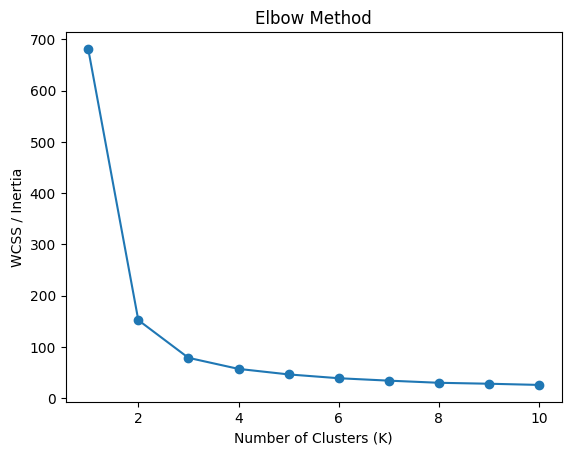

In [4]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Load data
iris = load_iris()
X = iris.data

# Calculate WCSS for different K values
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.show()

Important limitation

The elbow is sometimes not clearly visible. In that case, the Elbow Method alone may not provide a reliable answer.

You can combine it with:

- Silhouette Score

- Domain knowledge

- Cluster stability

- Business/scientific interpretation

In short

The Elbow Method plots K against WCSS/inertia and looks for the point where adding additional clusters provides diminishing improvements. This point, called the "elbow," is used as a practical estimate of the appropriate number of clusters


# 6. Generate synthetic data using make_blobs(n_samples=300, centers=4), apply KMeans clustering, and visualize the results with cluster centers. Use make_blobs, make_moons, and sklearn.datasets.load_wine() as specified.

- Below is a complete Python program that generates synthetic data using make_blobs(n_samples=300, centers=4), applies K-Means clustering, and visualizes the clusters along with their centroids. It also shows how make_moons and the Wine dataset can be loaded as specified.



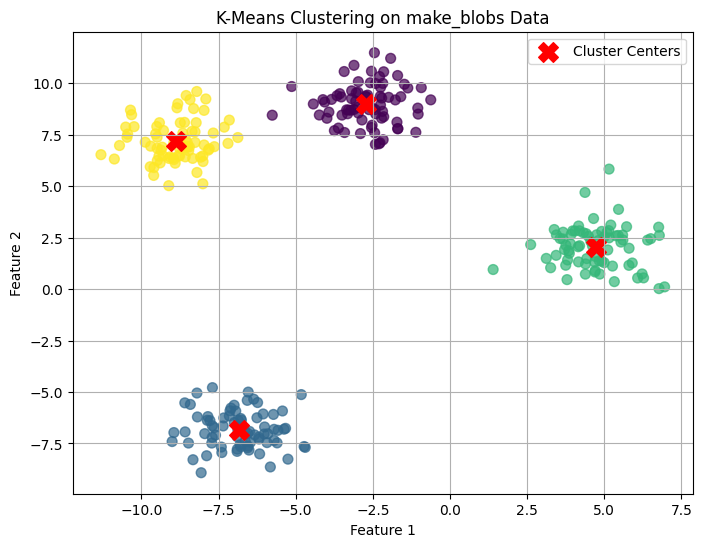

Wine dataset shape: (178, 13)
Wine target classes: ['class_0' 'class_1' 'class_2']


In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, load_wine
from sklearn.cluster import KMeans

# --------------------------------------------------
# 1. Generate synthetic data using make_blobs
# --------------------------------------------------
X, y = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=1.0,
    random_state=42
)

# --------------------------------------------------
# 2. Apply K-Means clustering
# --------------------------------------------------
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(X)

# Cluster labels and cluster centers
labels = kmeans.labels_
centers = kmeans.cluster_centers_

# --------------------------------------------------
# 3. Visualize the clusters and cluster centers
# --------------------------------------------------
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis",
    s=50,
    alpha=0.7
)

# Plot cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Cluster Centers"
)

plt.title("K-Means Clustering on make_blobs Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------------------------------
# 4. Generate data using make_moons
# --------------------------------------------------
X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.05,
    random_state=42
)

# --------------------------------------------------
# 5. Load the Wine dataset
# --------------------------------------------------
wine = load_wine()

print("Wine dataset shape:", wine.data.shape)
print("Wine target classes:", wine.target_names)

Explanation

- make_blobs() → creates well-separated synthetic clusters.

- KMeans(n_clusters=4) → divides the data into 4 clusters.

- labels_ → gives the cluster assigned to each data point.

- cluster_centers_ → gives the coordinates of the four cluster centers.

- make_moons() → generates two curved/non-linearly separable clusters and can be used to demonstrate where K-Means may struggle.

- load_wine() → loads the real Wine classification dataset from scikit-learn.

In short: make_blobs is ideal for demonstrating K-Means because its clusters are naturally compact and roughly spherical, making the resulting centroids easy to visualize.


# 7.  Load the Wine dataset, apply StandardScaler , and then train a DBSCAN model. Print the number of clusters found (excluding noise).

- Here is a simple Python program to load the Wine dataset, standardize the features using StandardScaler, apply DBSCAN, and print the number of clusters found excluding noise.


In [6]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import numpy as np

# 1. Load the Wine dataset
wine = load_wine()
X = wine.data

# 2. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply DBSCAN
dbscan = DBSCAN(eps=1.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

# 4. Count clusters excluding noise (-1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

# 5. Print results
print("Number of clusters found:", n_clusters)
print("Number of noise points:", np.sum(labels == -1))

Number of clusters found: 0
Number of noise points: 178


Explanation

- StandardScaler() puts all 13 Wine features on a comparable scale.

- DBSCAN() groups points based on density.

- DBSCAN assigns -1 to noise points.

- Therefore:


In [8]:
len(set(labels)) - (1 if -1 in labels else 0)

## counts only the actual clusters and excludes noise.


0

# 8. Generate moon-shaped synthetic data using make_moons(n_samples=200, noise=0.1), apply DBSCAN, and highlight the outliers in the plot.

- Here is a complete Python program that generates moon-shaped data, applies DBSCAN, and highlights the noise/outlier points.

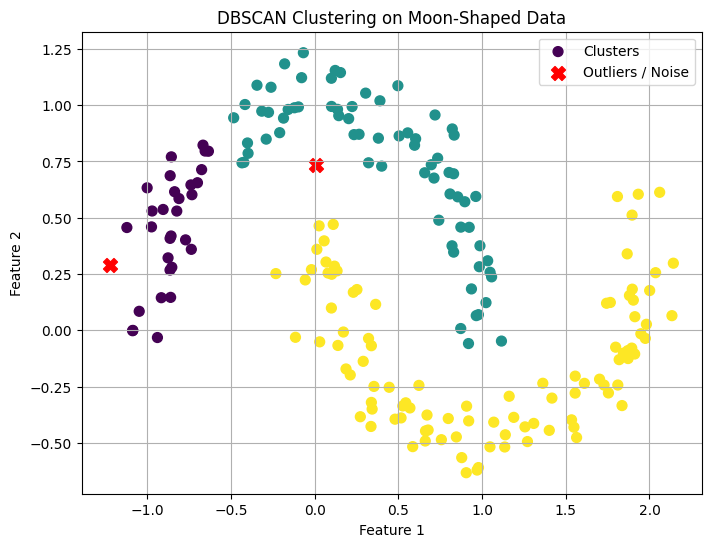

Number of clusters: 3
Number of outliers: 2


In [9]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

# 1. Generate moon-shaped synthetic data
X, y = make_moons(
    n_samples=200,
    noise=0.1,
    random_state=42
)

# 2. Apply DBSCAN
dbscan = DBSCAN(
    eps=0.2,
    min_samples=5
)

labels = dbscan.fit_predict(X)

# 3. Identify outliers/noise
outliers = labels == -1

# 4. Plot the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X[~outliers, 0],
    X[~outliers, 1],
    c=labels[~outliers],
    cmap="viridis",
    s=50,
    label="Clusters"
)

# Highlight outliers
plt.scatter(
    X[outliers, 0],
    X[outliers, 1],
    c="red",
    marker="X",
    s=100,
    label="Outliers / Noise"
)

plt.title("DBSCAN Clustering on Moon-Shaped Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

# 5. Print number of clusters and outliers
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_outliers = sum(outliers)

print("Number of clusters:", n_clusters)
print("Number of outliers:", n_outliers)

Key points

- make_moons() creates two interlocking moon-shaped clusters.

- DBSCAN is well suited to this type of non-linear cluster structure.

- DBSCAN labels noise/outliers as -1.

- The red X marks in the plot represent the detected outliers.

- eps=0.2 controls the neighborhood radius.

- min_samples=5 specifies the minimum number of nearby points needed to form a dense region.

In short: DBSCAN can identify the two curved moon-shaped clusters without assuming that clusters are spherical, while also identifying isolated points as noise.

# 9.  Load the Wine dataset, reduce it to 2D using PCA, then apply Agglomerative Clustering and visualize the result in 2D with a scatter plot.

- Here is a complete Python program to load the Wine dataset, standardize it, reduce it to 2 principal components using PCA, then perform Agglomerative Clustering and visualize the clusters.

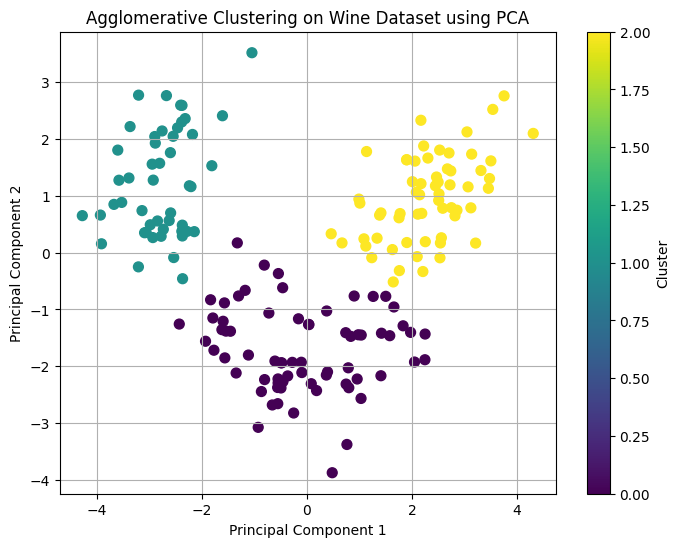

Explained variance ratio: [0.36198848 0.1920749 ]
Total variance explained: 0.5540633835693526


In [10]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering

# 1. Load the Wine dataset
wine = load_wine()
X = wine.data

# 2. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Reduce the data to 2 dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. Apply Agglomerative Clustering
clustering = AgglomerativeClustering(n_clusters=3)
labels = clustering.fit_predict(X_pca)

# 5. Visualize the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clustering on Wine Dataset using PCA")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

# 6. Print explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:",
      pca.explained_variance_ratio_.sum())

Steps performed

- Load Wine dataset → 178 samples and 13 features.

- StandardScaler → puts all features on a comparable scale.

- PCA → reduces 13 features to 2 principal components.

- Agglomerative Clustering → creates 3 clusters.

- Scatter plot → displays the resulting clusters in 2D.

The two axes in the plot represent PC1 and PC2, rather than the original Wine features.

In short:

Wine data → StandardScaler → PCA(2) → Agglomerative Clustering(3) → 2D scatter plot

# 10. You are working as a data analyst at an e-commerce company. The marketing team wants to segment customers based on their purchasing behavior to run targeted promotions. The dataset contains customer demographics and their product purchase history across categories.

# Describe your real-world data science workflow using clustering: ● Which clustering algorithm(s) would you use and why? ● How would you preprocess the data (missing values, scaling)? ● How would you determine the number of clusters? ● How would the marketing team benefit from your clustering analysis?

- Real-World Data Science Workflow for Customer Segmentation

For an e-commerce company, I would use clustering to group customers with similar demographics and purchasing behavior. These groups can then be used by the marketing team to create targeted promotions.

1. Choose the clustering algorithm

I would start with K-Means clustering because:

- It is simple and efficient for large customer datasets.

- It works well when customers can be represented by numerical behavioral features.

- The resulting clusters are easy to interpret for marketing purposes.

- It provides clear cluster centers, which can describe the typical behavior of each customer segment.

I would also consider Hierarchical Clustering if the dataset is relatively small and we want to understand relationships between customer groups through a dendrogram.

If the customer data contains unusual or noisy purchasing patterns, DBSCAN could also be tested because it can identify outliers rather than forcing every customer into a cluster.

Practical approach: Start with K-Means, then compare it with another suitable method if the resulting segments are not sufficiently meaningful.

2. Preprocess the data
Handle missing values

First, I would examine the dataset for missing values.

- Numerical variables → replace missing values with the median or an appropriate business-specific value.

- Categorical variables → replace missing values with the mode or an "Unknown" category.

- If a feature has an excessive number of missing values, consider removing it.

I would also check for duplicate customers and incorrect or extreme purchase values.

Convert categorical variables

Demographic variables such as:

- Gender
- Location
- Membership type

can be converted into numerical representations using techniques such as One-Hot Encoding.

Create useful behavioral features

Rather than using raw transaction records directly, I would create customer-level features such as:

- Total spending
- Number of purchases
- Average order value
- Purchase frequency
- Recency of last purchase
- Spending by product category
- Percentage of purchases in each category

This can make the clusters much more useful from a marketing perspective.

Scale the features

Scaling is important because clustering algorithms such as K-Means use distances.

For example, if:

- Annual spending ranges from ₹1,000–₹100,000
- Number of purchases ranges from 1–50

spending could dominate the distance calculation.

I would therefore typically use:

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

3. Determine the number of clusters

For K-Means, I would test several values of K, for example K = 2 to 10.

I would use:

Elbow Method

Plot K versus WCSS (Within-Cluster Sum of Squares).

The point where the reduction in WCSS begins to slow down is a possible choice for K.

Silhouette Score

The Silhouette Score measures how well customers fit within their assigned cluster compared with neighboring clusters.

In [12]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, labels)

A higher score generally indicates better separation and cohesion.

Business interpretation

Metrics alone should not determine the final segmentation. I would also examine whether the clusters represent meaningful and actionable customer groups.

For example, four interpretable segments may be more useful to the marketing team than seven technically better-separated but difficult-to-target groups.

4. Profile and interpret the clusters

After clustering, I would calculate the average characteristics of each cluster.

For example:

| Customer Segment           | Typical Behavior                     | Possible Marketing Approach    |
| -------------------------- | ------------------------------------ | ------------------------------ |
| High-value customers       | High spending and frequent purchases | Loyalty rewards                |
| Occasional buyers          | Low purchase frequency               | Repeat-purchase offers         |
| Category-focused customers | Strong preference for one category   | Category-specific promotions   |
| New/low-activity customers | Limited purchase history             | Welcome or introductory offers |


These descriptions should be based on the actual cluster statistics rather than assumptions.

5. How marketing benefits

The clustering analysis can help the marketing team:

- Personalize promotions according to customer behavior.
- Identify high-value customer groups for loyalty programs.
- Create category-specific campaigns.
- Design different discounts for different customer segments.
- Improve customer retention by identifying low-engagement groups.
- Allocate marketing budgets more efficiently.
- Recommend relevant products to customers with similar purchasing patterns.
- Measure campaign performance separately for each customer segment.

Overall workflow

Customer Data

      ↓

Data Cleaning

      ↓

Handle Missing Values

      ↓

Feature Engineering

      ↓

Encode Categorical Variables

      ↓

Scale Features

      ↓
Try K-Means / Other Suitable Algorithms


      ↓

Choose Number of Clusters

(Elbow + Silhouette + Business Meaning)

      ↓

Profile Customer Segments

      ↓

Targeted Marketing Campaigns

      ↓

Measure Campaign Results

Conclusion

I would primarily use K-Means because it is scalable and produces easily interpretable customer segments. I would clean and transform the customer data, handle missing values, encode categorical variables, and scale the features before clustering. The number of clusters would be selected using the Elbow Method, Silhouette Score, and business interpretability. Finally, the marketing team could use the resulting segments for personalized promotions, loyalty programs, retention campaigns, and more efficient marketing decisions.